# Machine Learning Champion Models (XGBoost Framework)

This notebook trains and evaluates gradient-boosted trees (XGBoost) for insurance risk estimation:
1. **Frequency XGBoost:** Poisson regression with exposure offset (`base_margin = ln(Exposure)`) and monotonic constraint on `BonusMalus`.
2. **Severity XGBoost:** Gamma regression on positive attritional claims ($<€100\text{k}$).
3. **Two-Part Pure Premium:** $\hat{\pi}_{\text{XGB}} = \hat{\mu}_{\text{Freq}} \times \hat{\mu}_{\text{Sev}}$.
4. **Direct Tweedie XGBoost:** Compound Poisson-Gamma ($p=1.5$).
5. **Benchmark Comparison:** Direct comparison against the Phase 3 GLM baseline across Poisson/Gamma/Tweedie deviances and Gini lift.

In [7]:
import os
import sys
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append(os.path.abspath(".."))
from src.models import (
    FrequencyPoissonGLM,
    SeverityGammaGLM,
    TwoPartGLM,
    FrequencyPoissonXGB,
    SeverityGammaXGB,
    TweedieXGB,
    TwoPartXGB,
)
from src.evaluation import poisson_deviance, gamma_deviance, tweedie_deviance, gini_coefficient

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 10

## 1. Train / Validation / Test Split

We use the exact same 20% holdout test set as Phase 3 to ensure valid benchmark comparison.

In [8]:
df = pd.read_parquet("../data/processed/abt_motor_portfolio.parquet")
train_full, test_df = train_test_split(df, test_size=0.20, random_state=42, shuffle=True)
train_df, val_df = train_test_split(train_full, test_size=0.125, random_state=42, shuffle=True)  # 70% train, 10% val, 20% test

print(f"Train set:      {len(train_df):,} policies")
print(f"Validation set: {len(val_df):,} policies")
print(f"Test set:       {len(test_df):,} policies")

Train set:      474,608 policies
Validation set: 67,802 policies
Test set:       135,603 policies


## 2. Frequency Modeling: Poisson XGBoost vs Poisson GLM

In [9]:
# Train Poisson XGBoost with early stopping on validation set
xgb_freq = FrequencyPoissonXGB(
    max_depth=4,
    learning_rate=0.05,
    n_estimators=300,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=20.0,
    enforce_monotonic_bm=True
)
xgb_freq.fit(train_df, df_val=val_df, early_stopping_rounds=25)

# Predictions on test set (with exposure offset)
test_xgb_freq_pred = xgb_freq.predict(test_df, offset_col="LogExposure")
xgb_freq_dev = poisson_deviance(test_df["ClaimNb"], test_xgb_freq_pred, exposure=test_df["Exposure_Capped"])
xgb_freq_gini = gini_coefficient(test_df["ClaimNb"], test_xgb_freq_pred, exposure=test_df["Exposure_Capped"])

# Baseline GLM for direct comparison
glm_freq = FrequencyPoissonGLM().fit(train_full, offset_col="LogExposure")
test_glm_freq_pred = glm_freq.predict(test_df, offset_col="LogExposure")
glm_freq_dev = poisson_deviance(test_df["ClaimNb"], test_glm_freq_pred, exposure=test_df["Exposure_Capped"])
glm_freq_gini = gini_coefficient(test_df["ClaimNb"], test_glm_freq_pred, exposure=test_df["Exposure_Capped"])

freq_comparison = pd.DataFrame({
    "Model": ["Poisson GLM (Baseline)", "Poisson XGBoost (Champion)"],
    "Test Poisson Deviance": [glm_freq_dev, xgb_freq_dev],
    "Test Frequency Gini": [glm_freq_gini, xgb_freq_gini],
    "Deviance Reduction (%)": ["-", f"{(glm_freq_dev - xgb_freq_dev) / glm_freq_dev * 100:.2f}%"]
})
display(freq_comparison)

,Model,Test Poisson Deviance,Test Frequency Gini,Deviance Reduction (%)
0,Poisson GLM (Baseline),0.605689,0.221444,-
1,Poisson XGBoost (Champion),0.581010,0.282597,4.07%


## 3. Severity Modeling: Gamma XGBoost vs Gamma GLM

In [10]:
xgb_sev = SeverityGammaXGB(
    max_depth=3,
    learning_rate=0.03,
    n_estimators=150,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=15.0
)
xgb_sev.fit(train_full)

glm_sev = SeverityGammaGLM().fit(train_full)

# Evaluate on test positive attritional claims
test_claims = test_df[
    (test_df["HasClaim"] == 1) & 
    (test_df["AvgClaimSeverity"] > 0) & 
    (test_df["AvgClaimSeverity"] < 100000.0)
].copy()

pred_xgb_sev = xgb_sev.predict(test_claims)
pred_glm_sev = glm_sev.predict(test_claims)

xgb_sev_dev = gamma_deviance(test_claims["AvgClaimSeverity"], pred_xgb_sev)
glm_sev_dev = gamma_deviance(test_claims["AvgClaimSeverity"], pred_glm_sev)

sev_comparison = pd.DataFrame({
    "Model": ["Gamma GLM (Baseline)", "Gamma XGBoost (Champion)"],
    "Test Gamma Deviance": [glm_sev_dev, xgb_sev_dev],
    "Mean Predicted Severity (€)": [f"€{pred_glm_sev.mean():.2f}", f"€{pred_xgb_sev.mean():.2f}"]
})
display(sev_comparison)

,Model,Test Gamma Deviance,Mean Predicted Severity (€)
0,Gamma GLM (Baseline),1.277176,€1700.62
1,Gamma XGBoost (Champion),1.275416,€1650.09


## 4. Pure Premium Compound Loss Cost: GLM vs XGBoost

In [13]:
# Two-Part Pure Premium Models
twopart_glm = TwoPartGLM(glm_freq, glm_sev)
twopart_xgb = TwoPartXGB(xgb_freq, xgb_sev)

pred_glm_pure = twopart_glm.predict_pure_premium(test_df)
pred_xgb_pure = twopart_xgb.predict_pure_premium(test_df)

# Direct Tweedie XGBoost
tweedie_xgb = TweedieXGB(tweedie_variance_power=1.5)
tweedie_xgb.fit(train_full)
pred_tweedie_xgb_pure = tweedie_xgb.predict(test_df)

# Evaluation on Test Set
dev_glm_twopart = tweedie_deviance(test_df["PurePremium"], pred_glm_pure, p=1.5, weights=test_df["Exposure_Capped"])
dev_xgb_twopart = tweedie_deviance(test_df["PurePremium"], pred_xgb_pure, p=1.5, weights=test_df["Exposure_Capped"])
dev_xgb_tweedie = tweedie_deviance(test_df["PurePremium"], pred_tweedie_xgb_pure, p=1.5, weights=test_df["Exposure_Capped"])

gini_glm_twopart = gini_coefficient(test_df["PurePremium"], pred_glm_pure, exposure=test_df["Exposure_Capped"])
gini_xgb_twopart = gini_coefficient(test_df["PurePremium"], pred_xgb_pure, exposure=test_df["Exposure_Capped"])
gini_xgb_tweedie = gini_coefficient(test_df["PurePremium"], pred_tweedie_xgb_pure, exposure=test_df["Exposure_Capped"])

overall_comparison = pd.DataFrame({
    "Pure Premium Model Architecture": [
        "Two-Part GLM (Poisson x Gamma)",
        "Two-Part XGBoost (Poisson x Gamma)",
        "Direct Tweedie XGBoost (p=1.5)"
    ],
    "Test Tweedie Deviance (p=1.5)": [dev_glm_twopart, dev_xgb_twopart, dev_xgb_tweedie],
    "Test Gini Index": [gini_glm_twopart, gini_xgb_twopart, gini_xgb_tweedie],
    "Mean Predicted Pure Premium": [
        f"€{pred_glm_pure.mean():.2f}",
        f"€{pred_xgb_pure.mean():.2f}",
        f"€{pred_tweedie_xgb_pure.mean():.2f}"
    ]
})
display(overall_comparison)

,Pure Premium Model Architecture,Test Tweedie Deviance (p=1.5),Test Gini Index,Mean Predicted Pure Premium
0,Two-Part GLM (Poisson x Gamma),77.682917,0.258657,€188.45
1,Two-Part XGBoost (Poisson x Gamma),76.869059,0.318732,€193.50
2,Direct Tweedie XGBoost (p=1.5),76.340695,0.320028,€145.54


## 5. Comparative Decile Calibration Curves

,Decile,Observed,Predicted_GLM,Predicted_XGB
0,1,59.984964,86.247408,70.064488
1,2,61.587418,109.350678,94.178535
2,3,103.145039,127.754540,110.034850
3,4,98.755414,140.710465,122.007874
4,5,125.039297,157.241382,132.838402
5,6,136.148999,169.350759,145.588638
6,7,158.968767,185.466195,165.134693
7,8,182.028209,217.270370,198.127083
8,9,321.167388,273.792443,261.852013
9,10,359.901420,401.379429,594.850547


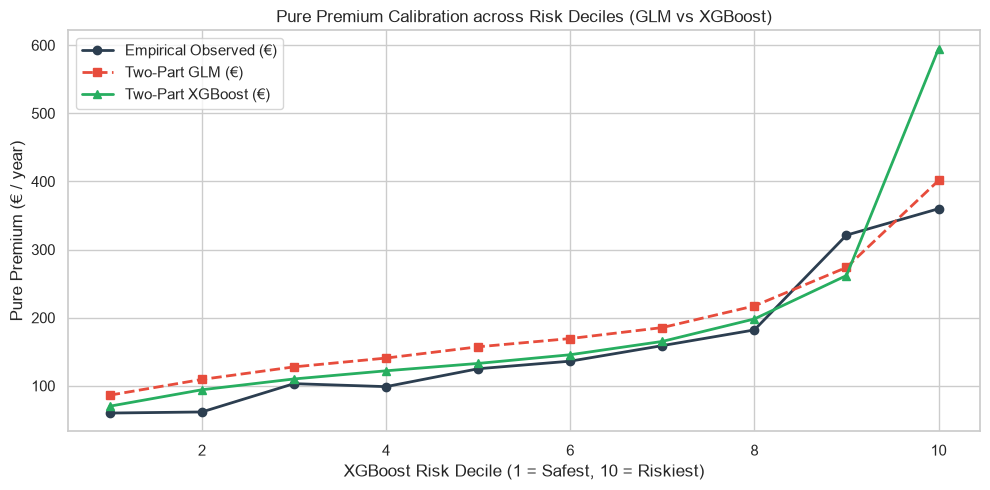

In [14]:
calib_comp = test_df.copy()
calib_comp["Pred_GLM"] = pred_glm_pure
calib_comp["Pred_XGB"] = pred_xgb_pure
calib_comp["Decile"] = pd.qcut(calib_comp["Pred_XGB"], q=10, labels=False) + 1

dec_summary = calib_comp.groupby("Decile").apply(
    lambda g: pd.Series({
        "Observed": g["TotalClaimAmount"].sum() / g["Exposure_Capped"].sum(),
        "Predicted_GLM": np.average(g["Pred_GLM"], weights=g["Exposure_Capped"]),
        "Predicted_XGB": np.average(g["Pred_XGB"], weights=g["Exposure_Capped"])
    })
).reset_index()

display(dec_summary)

plt.figure(figsize=(10, 5))
plt.plot(dec_summary["Decile"], dec_summary["Observed"], marker="o", lw=2, color="#2c3e50", label="Empirical Observed (€)")
plt.plot(dec_summary["Decile"], dec_summary["Predicted_GLM"], marker="s", lw=2, linestyle="--", color="#e74c3c", label="Two-Part GLM (€)")
plt.plot(dec_summary["Decile"], dec_summary["Predicted_XGB"], marker="^", lw=2, linestyle="-", color="#27ae60", label="Two-Part XGBoost (€)")

plt.title("Pure Premium Calibration across Risk Deciles (GLM vs XGBoost)", fontsize=12)
plt.xlabel("XGBoost Risk Decile (1 = Safest, 10 = Riskiest)")
plt.ylabel("Pure Premium (€ / year)")
plt.legend()
plt.tight_layout()
plt.show()